PART I: DATASET ACQUISITION AND UNDERSTANDING
--- First 10 Records ---
  Reservation_ID User_Category    Facility_Type  Lead_Time_Days  Participants  \
0       RES-1000       Student       Auditorium             5.0            50   
1       RES-1001      External       Auditorium             3.0            10   
2       RES-1002       Faculty       Auditorium             3.0            10   
3       RES-1003       Faculty  Conference Room             1.0            25   
4       RES-1004       Student       Auditorium             1.0            25   
5       RES-1005       Student   Sports Complex            20.0            25   
6       RES-1006       Student        Classroom            10.0            10   
7       RES-1007         Staff        Classroom            20.0           100   
8       RES-1008       Faculty       Auditorium             0.0            10   
9       RES-1009       Faculty  Conference Room             5.0            10   

   Actual_Attendance Usage_Status  Ti

/tmp/ipykernel_6692/1009465245.py:92: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['Lead_Time_Days'].fillna(df_clean['Lead_Time_Days'].median(), inplace=True)
/tmp/ipykernel_6692/1009465245.py:96: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[c

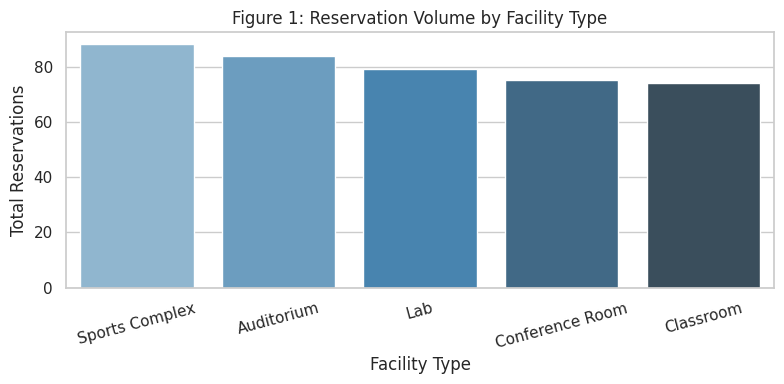

<Figure size 800x400 with 0 Axes>

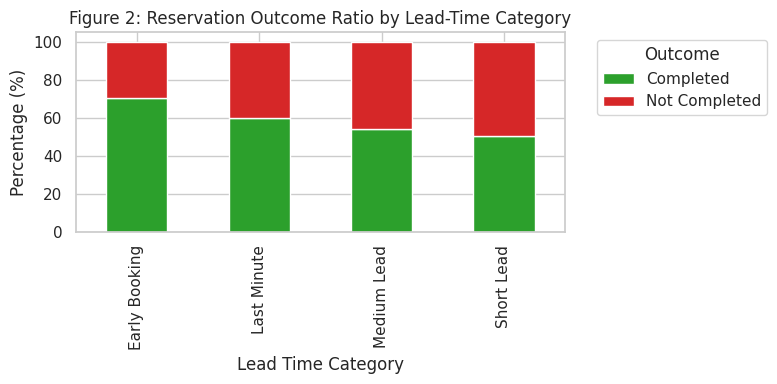


PART IV: DATA MINING AND PREDICTIVE MODELING
--- Model Performance Metrics ---
Accuracy:  0.5500
Precision: 0.5267
Recall:    0.5500
F1-Score:  0.5214

--- Confusion Matrix ---
[[35 11]
 [25  9]]

--- Top Predictors ---
Lead_Time_Days    0.339972
Participants      0.275895
Facility_Type     0.124451
User_Category     0.117300
Time_Slot         0.078831
Day_of_Week       0.063551
dtype: float64


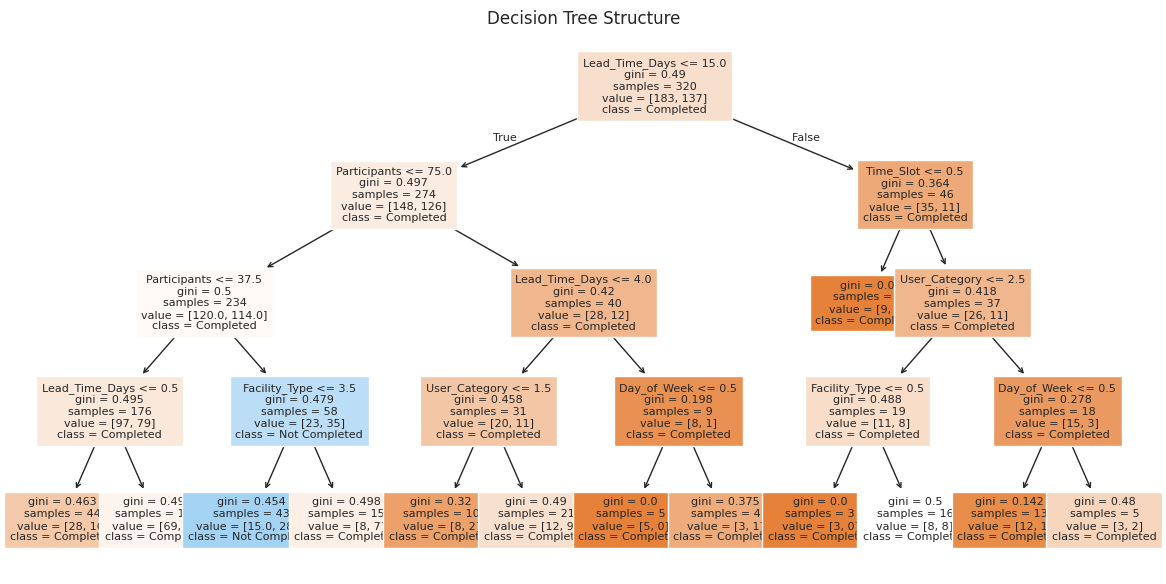


Notebook Execution Completed Successfully.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'


print("="*60)
print("PART I: DATASET ACQUISITION AND UNDERSTANDING")
print("="*60)

try:
    df_raw = pd.read_csv('facility_reservations.csv')
    print("Dataset loaded successfully.\n")
except FileNotFoundError:
    print("WARNING: 'facility_reservations.csv' not found. Creating synthetic dataset for demonstration purposes...")

    n_samples = 400
    df_raw = pd.DataFrame({
        'Reservation_ID': [f"RES-{1000+i}" for i in range(n_samples)],
        'User_Category': np.random.choice(['Student', 'Faculty', 'Staff', 'External'], n_samples, p=[0.5, 0.25, 0.15, 0.10]),
        'Facility_Type': np.random.choice(['Auditorium', 'Lab', 'Classroom', 'Conference Room', 'Sports Complex'], n_samples),
        'Lead_Time_Days': np.random.choice([ -1, 0, 1, 3, 5, 10, 20, np.nan], n_samples, p=[0.02, 0.2, 0.2, 0.2, 0.15, 0.1, 0.1, 0.03]),
        'Participants': np.random.choice([0, 10, 25, 50, 100], n_samples, p=[0.05, 0.3, 0.3, 0.2, 0.15]),
        'Actual_Attendance': np.random.choice([0, 8, 20, 45, 90], n_samples),
        'Usage_Status': np.random.choice(['Used', 'Cancelled', 'No-Show'], n_samples, p=[0.6, 0.25, 0.15]),
        'Time_Slot': np.random.choice(['Morning', 'Afternoon', 'Evening'], n_samples),
        'Day_of_Week': np.random.choice(['Weekday', 'Weekend'], n_samples, p=[0.8, 0.2])
    })

    df_raw = pd.concat([df_raw, df_raw.iloc[:5]], ignore_index=True)


df_original = df_raw.copy()

print("--- First 10 Records ---")
print(df_raw.head(10))

print("\n--- Dataset Dimensions ---")
print(f"Rows: {df_raw.shape[0]}, Columns: {df_raw.shape[1]}")

print("\n--- Variable Types & Data Info ---")
print(df_raw.info())

print("\n--- Summary Statistics (Numerical) ---")
print(df_raw.describe())

print("\n--- Summary Statistics (Categorical) ---")
print(df_raw.describe(include=['O']))

"""
Task 2 Answers:
- Target Variable: Usage_Status / Reservation_Outcome (Predicting whether reservation is completed vs cancelled/no-show)
- Predictor Candidates: User_Category, Facility_Type, Lead_Time_Days, Participants, Time_Slot, Day_of_Week
- Categorical Variables: User_Category, Facility_Type
- Numerical Variables: Lead_Time_Days, Participants
"""

"""
Task 3 Answers:
- API/Database Collection: Querying SQL database `SELECT * FROM reservations WHERE created_at >= ...` or REST API GET endpoints.
- Validation Check: Range check ensuring Lead_Time_Days >= 0 and Participants > 0 at submission time[cite: 1].
"""


print("\n" + "="*60)
print("PART II: DATA CLEANING AND FEATURE ENGINEERING")
print("="*60)

df_clean = df_original.copy()


print("1. Removing duplicate rows...")
initial_len = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Removed {initial_len - len(df_clean)} duplicate records.")

print("2. Handling missing & invalid numerical values...")

if 'Lead_Time_Days' in df_clean.columns:
    df_clean['Lead_Time_Days'] = df_clean['Lead_Time_Days'].apply(lambda x: np.nan if x < 0 else x)
    df_clean['Lead_Time_Days'].fillna(df_clean['Lead_Time_Days'].median(), inplace=True)

if 'Participants' in df_clean.columns:
    df_clean['Participants'] = df_clean['Participants'].apply(lambda x: np.nan if x <= 0 else x)
    df_clean['Participants'].fillna(df_clean['Participants'].median(), inplace=True)

if 'Actual_Attendance' in df_clean.columns:
    df_clean['Actual_Attendance'].fillna(0, inplace=True)

print("3. Generating Derived Variables...")

def categorize_lead_time(days):
    if days <= 2:
        return 'Last Minute'
    elif days <= 7:
        return 'Short Lead'
    elif days <= 14:
        return 'Medium Lead'
    else:
        return 'Early Booking'

df_clean['Lead_Time_Category'] = df_clean['Lead_Time_Days'].apply(categorize_lead_time)

df_clean['Reservation_Outcome'] = df_clean['Usage_Status'].apply(
    lambda x: 'Completed' if str(x).strip().lower() == 'used' else 'Not Completed'
)


df_clean['Attendance_Ratio'] = np.where(
    df_clean['Participants'] > 0,
    df_clean['Actual_Attendance'] / df_clean['Participants'],
    0.0
)
df_clean['Attendance_Ratio'] = df_clean['Attendance_Ratio'].clip(upper=1.0)


df_clean.to_csv('cleaned_facility_reservations.csv', index=False)
print("Clean dataset saved to 'cleaned_facility_reservations.csv'.\n")

print("--- Data Quality Summary ---")
print(df_clean[['Lead_Time_Category', 'Reservation_Outcome', 'Attendance_Ratio']].head(10))


print("\n" + "="*60)
print("PART III: EXPLORATORY DATA ANALYSIS")
print("="*60)

facility_counts = df_clean['Facility_Type'].value_counts()
print(f"Facility with Highest Reservation Count: {facility_counts.index[0]} ({facility_counts.iloc[0]} reservations)")

user_outcome = pd.crosstab(df_clean['User_Category'], df_clean['Reservation_Outcome'], normalize='index') * 100
highest_cancellation_user = user_outcome['Not Completed'].idxmax()
print(f"User Category with Highest Non-Completion Rate: {highest_cancellation_user} ({user_outcome.loc[highest_cancellation_user, 'Not Completed']:.2f}% denominator: total reservations by category)")

lead_outcome = pd.crosstab(df_clean['Lead_Time_Category'], df_clean['Reservation_Outcome'], normalize='index') * 100
print("\n--- Non-Completion Rate by Lead-Time Category ---")
print(lead_outcome)

plt.figure(figsize=(8, 4))
sns.barplot(x=facility_counts.index, y=facility_counts.values, palette='Blues_d')
plt.title('Figure 1: Reservation Volume by Facility Type')
plt.xlabel('Facility Type')
plt.ylabel('Total Reservations')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('facility_counts.png')
plt.show()

plt.figure(figsize=(8, 4))
lead_outcome.plot(kind='bar', stacked=True, color=['#2ca02c', '#d62728'], figsize=(8, 4))
plt.title('Figure 2: Reservation Outcome Ratio by Lead-Time Category')
plt.xlabel('Lead Time Category')
plt.ylabel('Percentage (%)')
plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('lead_time_outcome.png')
plt.show()

print("\n" + "="*60)
print("PART IV: DATA MINING AND PREDICTIVE MODELING")
print("="*60)


feature_cols = ['User_Category', 'Facility_Type', 'Lead_Time_Days', 'Participants', 'Time_Slot', 'Day_of_Week']
X = df_clean[feature_cols].copy()
y = df_clean['Reservation_Outcome'].copy()

label_encoders = {}
for col in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

target_le = LabelEncoder()
y_encoded = target_le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=RANDOM_STATE, stratify=y_encoded
)

clf = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("--- Model Performance Metrics ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)

importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\n--- Top Predictors ---")
print(importances)


plt.figure(figsize=(12, 6))
plot_tree(clf, feature_names=feature_cols, class_names=target_le.classes_, filled=True, fontsize=8)
plt.title("Decision Tree Structure")
plt.tight_layout()
plt.savefig('decision_tree.png')
plt.show()

print("\nNotebook Execution Completed Successfully.")